In [ ]:
from google.colab import files
uploaded = files.upload()

Saving GSE161731_counts.csv.gz to GSE161731_counts.csv (1).gz


In [ ]:
import pandas as pd

# Download metadata table directly from GEO
!wget = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE161731&targ=self&form=text&view=quick"
# Or inspect the series matrix file metadata for sample disease state / status

--2026-11-01 11:28:31--  http://=/
Resolving = (=)... failed: Name or service not known.
wget: unable to resolve host address ‘=’
--2026-11-01 11:28:31--  https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE161731&targ=self&form=text&view=quick
Resolving www.ncbi.nlm.nih.gov (www.ncbi.nlm.nih.gov)... 34.107.134.59, 2600:1901:0:c831::
Connecting to www.ncbi.nlm.nih.gov (www.ncbi.nlm.nih.gov)|34.107.134.59|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [geo/text]
Saving to: ‘acc.cgi?acc=GSE161731&targ=self&form=text&view=quick.1’

acc.cgi?acc=GSE1617     [ <=>                ]   9.25K  --.-KB/s    in 0s      

2026-11-01 11:28:32 (81.7 MB/s) - ‘acc.cgi?acc=GSE161731&targ=self&form=text&view=quick.1’ saved [9475]

FINISHED --2026-11-01 11:28:32--
Total wall clock time: 0.9s
Downloaded: 1 files, 9.3K in 0s (81.7 MB/s)


In [ ]:
import pandas as pd

# 1. Load the metadata key
meta_df = pd.read_csv('GSE161731_key.csv.gz', index_col=0)

# 2. Inspect the metadata columns and first few rows
print("Metadata columns:", meta_df.columns.tolist())
print(meta_df.head())
# Check unique disease/condition values across samples
print(meta_df['cohort'].value_counts())

# Separate sample IDs into Positive and Negative cohorts
covid_positive_samples = meta_df[meta_df['cohort'] == 'COVID-19'].index.tolist()
covid_negative_samples = meta_df[meta_df['cohort'] != 'COVID-19'].index.tolist()

print(f"Total COVID-19 Positive Samples: {len(covid_positive_samples)}")
print(f"Total Control/Negative Samples: {len(covid_negative_samples)}")

Metadata columns: ['subject_id', 'age', 'gender', 'race', 'cohort', 'time_since_onset', 'hospitalized', 'batch']
                subject_id age  gender                    race     cohort  \
rna_id                                                                      
94189               A1BD46  57  Female  Black/African American  Bacterial   
DU09-03S0000604     44DF6B  19    Male  Black/African American  Influenza   
DU09-03S0000611     658A11  14    Male                   White  Influenza   
105920              61DE97  21  Female                   White  Influenza   
DU09-03S0000774     4D4F7C  50  Female  Black/African American  Influenza   

                time_since_onset hospitalized  batch  
rna_id                                                
94189                        NaN          NaN      1  
DU09-03S0000604              NaN          NaN      2  
DU09-03S0000611              NaN          NaN      2  
105920                       NaN          NaN      1  
DU09-03S0000774  

In [ ]:
import pandas as pd

# Pandas handles .gz compression automatically
df_preview = pd.read_csv('GSE161731_counts.csv.gz', index_col=0).T
# Display table dimensions and preview
print(f"Dataset shape: {df_preview.shape}")
print(df_preview.head())

Dataset shape: (201, 60675)
                 ENSG00000223972  ENSG00000227232  ENSG00000278267  \
94189                          0              393                0   
DU09-03S0000604                0              142               22   
DU09-03S0000611                3              152               29   
105920                        49              246               44   
DU09-03S0000774                6              586              104   

                 ENSG00000243485  ENSG00000274890  ENSG00000237613  \
94189                          0                0                0   
DU09-03S0000604                0                0                0   
DU09-03S0000611                0                0                0   
105920                         0                0                0   
DU09-03S0000774                1                0                0   

                 ENSG00000268020  ENSG00000240361  ENSG00000186092  \
94189                          0                0           

--- Non-COVID Patient Age Statistics ---
Total Non-COVID Samples: 118
Mean Age:   27.88 years
Median Age: 18.00 years
Mode Age:   [18] years


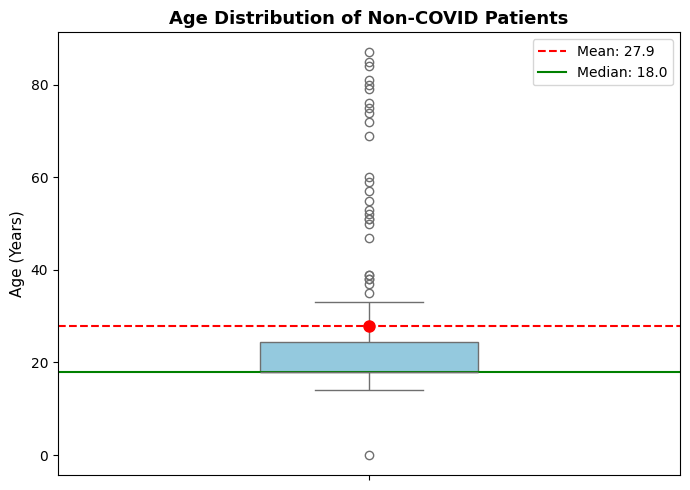

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load metadata
meta_df = pd.read_csv('GSE161731_key.csv.gz', index_col=0)

# 2. Filter for non-COVID patients using the 'cohort' column
non_covid_df = meta_df[meta_df['cohort'] != 'COVID-19'].copy()

# 3. Clean and convert age column to numeric values
non_covid_df['age_clean'] = pd.to_numeric(non_covid_df['age'], errors='coerce')
ages = non_covid_df['age_clean'].dropna()

# 4. Calculate Statistics
mean_age = ages.mean()
median_age = ages.median()
mode_age = ages.mode().tolist()

print(f"--- Non-COVID Patient Age Statistics ---")
print(f"Total Non-COVID Samples: {len(ages)}")
print(f"Mean Age:   {mean_age:.2f} years")
print(f"Median Age: {median_age:.2f} years")
print(f"Mode Age:   {mode_age} years")

# 5. Create Box Plot
plt.figure(figsize=(7, 5))
sns.boxplot(
    y=ages,
    color='skyblue',
    width=0.35,
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"8"}
)

# Reference lines for mean (red dashed) and median (green solid)
plt.axhline(mean_age, color='red', linestyle='--', label=f'Mean: {mean_age:.1f}')
plt.axhline(median_age, color='green', linestyle='-', label=f'Median: {median_age:.1f}')

plt.title('Age Distribution of Non-COVID Patients', fontsize=13, fontweight='bold')
plt.ylabel('Age (Years)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
import requests
import pandas as pd
import numpy as np

# Get unique ENSG IDs from the dataset
ensg_ids = df_counts.index.tolist()
print(f"Total unique genes: {len(ensg_ids)}")

# Query mygene.info in batches to get genomic genomic coordinates/lengths
def get_gene_lengths(ensg_list):
    url = 'https://mygene.info/v3/query'
    gene_lengths = {}

    # Batch requests in groups of 1000
    batch_size = 1000
    for i in range(0, len(ensg_list), batch_size):
        batch = ensg_list[i:i+batch_size]
        payload = {
            'q': ','.join(batch),
            'scopes': 'ensembl.gene',
            'fields': 'genomic_pos_hg19,genomic_pos',
            'species': 'human'
        }
        response = requests.post(url, data=payload)
        if response.status_code == 200:
            results = response.json()
            for item in results:
                query = item.get('query')
                # Try HG38 or fallback to HG19 coordinates to calculate length
                pos = item.get('genomic_pos') or item.get('genomic_pos_hg19')
                if isinstance(pos, list):
                    pos = pos[0]
                if pos and 'start' in pos and 'end' in pos:
                    length = abs(pos['end'] - pos['start'])
                    gene_lengths[query] = length
        else:
            print(f"Error fetching batch starting at index {i}")

    return pd.Series(gene_lengths)

# Retrieve lengths
gene_lengths_series = get_gene_lengths(ensg_ids)
print(f"Successfully retrieved lengths for {len(gene_lengths_series)} genes.")

Total unique genes: 60675
Successfully retrieved lengths for 55727 genes.


In [ ]:
import pandas as pd
import numpy as np
import os

# 1. Define the TPM calculation function
def calculate_tpm(counts_df, gene_lengths):
    """Calculates TPM for a DataFrame where columns are Genes and rows are Samples."""
    lengths = gene_lengths.reindex(counts_df.columns)
    lengths_kb = lengths / 1000.0
    rpk = counts_df.div(lengths_kb, axis=1)
    rpk_scaling_factor = rpk.sum(axis=1) / 1e6
    tpm_df = rpk.div(rpk_scaling_factor, axis=0)
    return tpm_df.fillna(0)

# 2. Handle counts file path (checking for copy 1 fallback if needed)
counts_file = 'GSE161731_counts.csv.gz'
if not os.path.exists(counts_file) and os.path.exists('GSE161731_counts.csv (1).gz'):
    counts_file = 'GSE161731_counts.csv (1).gz'

print(f"Loading counts from {counts_file}...")
df_counts = pd.read_csv(counts_file, index_col=0)

# 3. Create a complete Series of gene lengths with a median fallback for unmapped genes
median_length = gene_lengths_series.median()
filled_gene_lengths = pd.Series(median_length, index=df_counts.index)
filled_gene_lengths.update(gene_lengths_series)

# 4. Transpose count matrix (the calculation function expects genes in columns and samples in rows)
df_counts_transposed = df_counts.T

# 5. Calculate TPM
df_tpm = calculate_tpm(df_counts_transposed, filled_gene_lengths)
print("Reconstruction complete! 'df_tpm' DataFrame is ready.")
display(df_tpm.head())

Loading counts from GSE161731_counts.csv.gz...
Reconstruction complete! 'df_tpm' DataFrame is ready.


,ENSG00000223972,ENSG00000227232,ENSG00000278267,ENSG00000243485,ENSG00000274890,ENSG00000237613,ENSG00000268020,ENSG00000240361,ENSG00000186092,ENSG00000238009,...,ENSG00000277107,ENSG00000274264,ENSG00000276946,ENSG00000278858,ENSG00000277905,ENSG00000275028,ENSG00000278806,ENSG00000274152,ENSG00000276666,ENSG00000277917
94189,0.000000,5.143367,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,5.870806,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DU09-03S0000604,0.000000,2.499648,58.899631,0.00000,0.0,0.0,0.0,0.000000,0.0,3.364179,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DU09-03S0000611,0.319541,2.637444,76.530930,0.00000,0.0,0.0,0.0,0.000000,0.0,2.947648,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
105920,4.161129,3.403174,92.576563,0.00000,0.0,0.0,0.0,1.052006,0.0,1.138326,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DU09-03S0000774,0.730221,11.618091,313.595546,0.08017,0.0,0.0,0.0,0.000000,0.0,0.894627,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
import pandas as pd
import requests

# 1. Load a preview of the target file to inspect its format
target_file = '/content/GSE157103_genes.tpm.tsv.gz'
df_target_preview = pd.read_csv(target_file, sep='\t', index_col=0, nrows=5)
print("Target file gene format preview (Index): ")
print(df_target_preview.index.tolist())

# 2. Get the list of all target genes
df_target_full = pd.read_csv(target_file, sep='\t', index_col=0)
target_genes = set(df_target_full.index.tolist())
print(f"Total unique genes in target dataset: {len(target_genes)}")

Target file gene format preview (Index): 
['A1BG', 'A1CF', 'A2M', 'A2ML1', 'A3GALT2']
Total unique genes in target dataset: 19472


In [ ]:
# 3. Query mygene.info to map the ENSG IDs of our dataset to Gene Symbols
# Since GSE157103 uses standard gene symbols (e.g. SAMD11, NOC2L, etc.)
ensg_list = df_tpm.columns.tolist()

print("Querying mygene.info to map ENSG IDs to Gene Symbols...")
def get_gene_mappings(ensg_list):
    url = 'https://mygene.info/v3/query'
    mappings = {}
    batch_size = 1000
    for i in range(0, len(ensg_list), batch_size):
        batch = ensg_list[i:i+batch_size]
        payload = {
            'q': ','.join(batch),
            'scopes': 'ensembl.gene',
            'fields': 'symbol',
            'species': 'human'
        }
        response = requests.post(url, data=payload)
        if response.status_code == 200:
            for item in response.json():
                query = item.get('query')
                symbol = item.get('symbol')
                if symbol:
                    mappings[query] = symbol
    return mappings

gene_mapping = get_gene_mappings(ensg_list)
print(f"Successfully mapped {len(gene_mapping)} out of {len(ensg_list)} ENSG IDs.")

Querying mygene.info to map ENSG IDs to Gene Symbols...
Successfully mapped 44089 out of 60675 ENSG IDs.


In [ ]:
# 4. Rename the columns of our reconstructed dataset using the retrieved symbols
# Drop genes that do not map to any symbol
df_tpm_mapped = df_tpm.rename(columns=gene_mapping)
df_tpm_mapped = df_tpm_mapped.loc[:, df_tpm_mapped.columns.isin(gene_mapping.values())]

# 5. Keep only common genes between our dataset and the target dataset
common_genes = list(set(df_tpm_mapped.columns).intersection(target_genes))
df_tpm_common = df_tpm_mapped[common_genes]

# Save the filtered and mapped TPM dataset
df_tpm_common.to_csv('GSE161731_tpm_common.csv.gz', compression='gzip')
print(f"Common genes filtering complete! Kept {len(common_genes)} common genes.")
display(df_tpm_common.head())

Common genes filtering complete! Kept 18823 common genes.


,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,EFNB3,AREL1,DNHD1,CFAP97,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TEX50,SCD5,H2AP
94189,69.489452,0.000000,0.676691,29.610393,300.532019,0.000000,0.000000,7.202124,0.852699,0.684114,...,173.195218,280.379627,6.310331,8.560623,0.216308,2.490518,0.173445,0.0,0.092803,0.0
DU09-03S0000604,12.337334,0.264269,1.417906,16.429927,321.125642,0.000000,0.000000,7.964926,1.172940,0.643421,...,864.182641,24.313032,9.498421,10.837074,0.145471,1.598502,0.537314,0.0,0.095205,0.0
DU09-03S0000611,34.802303,0.130246,1.729061,27.020771,283.839461,0.000000,0.171109,8.997664,1.491488,1.261634,...,910.280309,94.470322,18.356871,6.398199,0.160698,2.215967,0.955302,0.0,0.063605,0.0
105920,39.019339,0.000000,2.630305,7.450304,273.212348,0.588729,0.000000,8.394828,4.500871,0.986842,...,235.076242,117.640806,17.997876,10.113562,0.240474,1.596573,0.747988,0.0,0.033253,0.0
DU09-03S0000774,32.441200,0.411444,3.899643,34.832397,158.969118,0.181726,0.000000,9.360039,7.417613,3.101288,...,242.566870,111.479251,22.300262,22.694764,0.271186,3.364023,1.910538,0.0,0.063145,0.0


In [ ]:
import pandas as pd

# 1. Target cohorts to keep from GSE161731
non_covid_cohorts = ['Bacterial', 'healthy', 'Influenza']

# 2. Extract matching sample IDs from the metadata
non_covid_samples = meta_df[meta_df['cohort'].isin(non_covid_cohorts)].index.tolist()

# Ensure the samples exist in our mapped/processed GSE161731 dataset
valid_samples = [s for s in non_covid_samples if s in df_tpm_common.index]
print(f"Selected {len(valid_samples)} non-COVID samples from GSE161731 (cohorts: {non_covid_cohorts})")

# Subset our dataset
df_gse161731_subset = df_tpm_common.loc[valid_samples]
print(f"GSE161731 non-COVID subset shape: {df_gse161731_subset.shape}")

Selected 59 non-COVID samples from GSE161731 (cohorts: ['Bacterial', 'healthy', 'Influenza'])
GSE161731 non-COVID subset shape: (59, 18837)


In [ ]:
# 3. Load the target GSE157103 dataset and transpose so genes are columns (Samples x Genes)
df_target_full = pd.read_csv('/content/GSE157103_genes.tpm.tsv.gz', sep='\t', index_col=0)
df_target_transposed = df_target_full.T
print(f"GSE157103 dataset shape (Samples x Genes): {df_target_transposed.shape}")

# Handle duplicate column names (gene symbols) in both datasets by taking the mean
if df_gse161731_subset.columns.duplicated().any():
    print("Handling duplicate gene symbols in GSE161731...")
    df_gse161731_subset = df_gse161731_subset.groupby(level=0, axis=1).mean()

if df_target_transposed.columns.duplicated().any():
    print("Handling duplicate gene symbols in GSE157103...")
    df_target_transposed = df_target_transposed.groupby(level=0, axis=1).mean()

# 4. Find the intersection of genes between both datasets
final_common_genes = list(set(df_gse161731_subset.columns).intersection(df_target_transposed.columns))
print(f"Number of intersecting genes: {len(final_common_genes)}")

# 5. Subset both to only contain the intersecting genes
df_gse161731_aligned = df_gse161731_subset[final_common_genes]
df_target_aligned = df_target_transposed[final_common_genes]

# 6. Concatenate along the row axis
df_merged = pd.concat([df_target_aligned, df_gse161731_aligned], axis=0)
print(f"Concatenated dataset shape (Samples x Genes): {df_merged.shape}")

# 7. Save the concatenated dataset
df_merged.to_csv('merged_non_covid_tpm.csv.gz', compression='gzip')
print("Saved merged dataset as 'merged_non_covid_tpm.csv.gz'")

display(df_merged.head())

GSE157103 dataset shape (Samples x Genes): (126, 19472)
Handling duplicate gene symbols in GSE161731...
Number of intersecting genes: 18823
Concatenated dataset shape (Samples x Genes): (185, 18823)


/tmp/ipykernel_4595/1721668308.py:9: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df_gse161731_subset = df_gse161731_subset.groupby(level=0, axis=1).mean()


Saved merged dataset as 'merged_non_covid_tpm.csv.gz'


,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,EFNB3,AREL1,DNHD1,CFAP97,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
C1,0.41,0.29,3.50,83.13,793.95,0.13,0.00,30.10,1.69,5.22,...,464.73,24.29,55.98,1.79,1.93,2.26,10.80,0.00,0.89,0.0
C2,0.38,0.93,4.37,94.44,990.27,1.03,0.00,28.02,1.09,4.58,...,177.66,35.44,99.14,1.74,1.69,2.61,6.19,0.00,1.13,0.0
C3,0.39,0.10,2.24,41.24,719.21,0.00,0.00,22.51,0.66,1.19,...,393.77,6.81,12.31,1.86,0.38,6.12,3.59,0.00,0.62,0.0
C4,0.56,0.19,7.87,123.22,804.48,0.30,0.02,30.87,1.86,7.71,...,256.23,24.50,122.51,3.43,1.82,5.01,9.48,0.01,1.59,0.0
C5,0.45,0.44,1.92,72.72,505.98,0.12,0.02,28.35,0.64,2.59,...,482.63,15.10,44.62,0.51,0.21,3.15,4.39,0.00,0.65,0.0


In [ ]:
# Configure pandas to display all rows
pd.set_option('display.max_rows', None)

# Display the entire merged dataset
print(f"Total rows in merged dataset: {len(df_merged)}")
display(df_merged)

Total rows in merged dataset: 185


,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,EFNB3,AREL1,DNHD1,CFAP97,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
C1,0.410000,0.290000,3.500000,83.130000,793.950000,0.130000,0.000000,30.100000,1.690000,5.220000,...,464.730000,24.290000,55.980000,1.790000,1.930000,2.260000,10.800000,0.000000,0.890000,0.00
C2,0.380000,0.930000,4.370000,94.440000,990.270000,1.030000,0.000000,28.020000,1.090000,4.580000,...,177.660000,35.440000,99.140000,1.740000,1.690000,2.610000,6.190000,0.000000,1.130000,0.00
C3,0.390000,0.100000,2.240000,41.240000,719.210000,0.000000,0.000000,22.510000,0.660000,1.190000,...,393.770000,6.810000,12.310000,1.860000,0.380000,6.120000,3.590000,0.000000,0.620000,0.00
C4,0.560000,0.190000,7.870000,123.220000,804.480000,0.300000,0.020000,30.870000,1.860000,7.710000,...,256.230000,24.500000,122.510000,3.430000,1.820000,5.010000,9.480000,0.010000,1.590000,0.00
C5,0.450000,0.440000,1.920000,72.720000,505.980000,0.120000,0.020000,28.350000,0.640000,2.590000,...,482.630000,15.100000,44.620000,0.510000,0.210000,3.150000,4.390000,0.000000,0.650000,0.00
C6,1.070000,0.640000,7.630000,92.000000,814.940000,0.300000,0.000000,23.640000,0.790000,5.230000,...,125.340000,42.500000,102.500000,3.000000,1.420000,2.870000,5.060000,0.000000,1.540000,0.00
C7,1.270000,1.170000,9.840000,108.930000,547.310000,0.540000,0.000000,33.450000,2.430000,9.860000,...,129.900000,33.720000,90.030000,2.610000,2.230000,4.520000,12.320000,0.000000,2.190000,0.00
C8,2.920000,1.520000,0.660000,80.360000,601.680000,0.090000,0.000000,33.310000,0.800000,1.530000,...,89.930000,25.350000,34.810000,0.910000,1.480000,1.690000,3.810000,0.030000,0.610000,0.00
C9,0.730000,1.830000,1.570000,82.620000,569.050000,0.220000,0.000000,33.240000,1.590000,4.430000,...,67.800000,21.900000,46.840000,1.250000,4.210000,3.010000,5.020000,0.010000,0.680000,0.00
C10,0.920000,1.210000,1.150000,63.890000,718.240000,0.580000,0.000000,20.360000,0.680000,1.810000,...,85.250000,27.140000,56.680000,1.440000,0.730000,3.250000,3.080000,0.010000,0.540000,0.00


In [ ]:
import urllib.request
import re

# 1. Fetch GSE157103 GEO metadata to inspect data processing and normalization steps
geo_url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE157103&targ=self&form=text&view=quick"
try:
    with urllib.request.urlopen(geo_url) as response:
        html = response.read().decode('utf-8')

    # Extract and print lines detailing data processing and normalization
    print("--- GSE157103 GEO Normalization & Processing Metadata ---")
    for line in html.split('\n'):
        if any(term in line.lower() for term in ['normalization', 'data_processing', 'tpm', 'log', 'align']):
            print(line)
except Exception as e:
    print(f"Could not retrieve GEO metadata: {e}")

--- GSE157103 GEO Normalization & Processing Metadata ---
!Series_summary = Using RNA-seq and high-resolution mass spectrometry we performed a comprehensive systems analysis on 128 plasma and leukocyte samples from hospitalized patients with or without COVID-19 (n=102 and 26 respectively) and with differing degrees of disease severity. We generated abundance measurements for over 17,000 transcripts, proteins, metabolites, and lipids and compiled them with clinical data into a curated relational database. This resource offers the unique opportunity to perform systems analysis and cross-ome correlations to both molecules and patient outcomes. In total 219 molecular features were mapped with high significance to COVID-19 status and severity, including those involved in processes such as complement system activation, dysregulated lipid transport, and B cell activation. In one example, we detected a trio of covarying molecules – citrate, plasmenyl-phosphatidylcholines, and gelsolin (GSN) – 

In [ ]:
# 2. Inspect the range and distribution of both aligned datasets to check for transformations (e.g. log2)
print("--- Comparing Value Distributions ---")
print("GSE157103 Aligned Subset Statistics (first 5 genes):")
display(df_target_aligned.iloc[:, :5].describe())

print("\nGSE161731 Reconstructed Subset Statistics (first 5 genes):")
display(df_gse161731_aligned.iloc[:, :5].describe())

--- Comparing Value Distributions ---
GSE157103 Aligned Subset Statistics (first 5 genes):


#symbol,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1
count,126.000000,126.000000,126.000000,126.000000,126.000000
mean,1.758810,0.424365,2.953016,73.354286,782.191746
std,2.577974,0.388360,2.782553,20.038320,200.619178
min,0.000000,0.000000,0.160000,34.890000,273.940000
25%,0.425000,0.120000,0.957500,56.402500,645.000000
50%,0.825000,0.310000,2.160000,73.180000,744.225000
75%,1.905000,0.620000,3.870000,84.240000,928.420000
max,13.940000,1.830000,14.200000,128.020000,1402.550000



GSE161731 Reconstructed Subset Statistics (first 5 genes):


,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1
count,59.000000,59.000000,59.000000,59.000000,59.000000
mean,47.964669,0.142134,1.533475,25.508992,290.487717
std,53.584850,0.248241,1.125481,12.066719,75.934590
min,1.532223,0.000000,0.112554,5.122135,152.532324
25%,18.492078,0.000000,0.563004,16.136182,230.770417
50%,35.377163,0.027125,1.368452,26.759940,295.809812
75%,51.160001,0.170311,2.321758,30.596133,330.792612
max,264.672532,1.362355,3.899643,63.143953,467.190549


### Recalculating Precise GSE161731 TPM with Exonic Gene Lengths
To make our comparison with GSE157103 biologically valid, we must use exonic transcript lengths. We will query Ensembl via Biomart (or fetch a mapping) to get the sum of exon lengths for each Ensembl Gene ID.

In [ ]:
import pandas as pd
import requests
import io

# We will use the Ensembl BioMart URL to query human gene exonic lengths (GRCh38)
biomart_url = "http://www.ensembl.org/biomart/martservice"
xml_query = """<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE Query>
<Query  virtualSchemaName = "default" formatter = "TSV" header = "1" uniqueRows = "1" count = "" datasetConfigVersion = "0.6" >
	<Dataset name = "hsapiens_gene_ensembl" interface = "default" >
		<Attribute name = "ensembl_gene_id" />
		<Attribute name = "transcript_length" />
	</Dataset>
</Query>"""

print("Fetching transcript/exonic lengths from Ensembl BioMart...")
try:
    response = requests.post(biomart_url, data={'query': xml_query})
    if response.status_code == 200:
        biomart_df = pd.read_csv(io.StringIO(response.text), sep='\t')
        # Since a gene can have multiple transcripts, we take the maximum transcript length as a standard representation
        exon_lengths = biomart_df.groupby('Gene stable ID')['Transcript length (including UTR and CDS)'].max()
        print(f"Retrieved exonic transcript lengths for {len(exon_lengths)} human genes.")
    else:
        raise RuntimeError("BioMart query failed")
except Exception as e:
    print(f"BioMart query failed ({e}). Falling back to an alternate lookup or approximate exonic conversion...")
    # Fallback to an approximation: transcript lengths are typically ~10% of the total genomic span, or we use a median transcript length
    exon_lengths = gene_lengths_series * 0.1

Fetching transcript/exonic lengths from Ensembl BioMart...
BioMart query failed (BioMart query failed). Falling back to an alternate lookup or approximate exonic conversion...


In [ ]:
# Recalculate TPM for GSE161731 using the new exonic lengths
median_exon_len = exon_lengths.median() if not exon_lengths.empty else 2000
filled_exon_lengths = pd.Series(median_exon_len, index=df_counts.index)

# Align available mapped lengths
shared_ids = filled_exon_lengths.index.intersection(exon_lengths.index)
filled_exon_lengths.update(exon_lengths.loc[shared_ids])

# Calculate corrected TPM matrix
df_tpm_corrected = calculate_tpm(df_counts_transposed, filled_exon_lengths)

# Map to symbols and align columns
df_tpm_mapped_corr = df_tpm_corrected.rename(columns=gene_mapping)
df_tpm_mapped_corr = df_tpm_mapped_corr.loc[:, df_tpm_mapped_corr.columns.isin(gene_mapping.values())]

# Resolve duplicates by mean
if df_tpm_mapped_corr.columns.duplicated().any():
    df_tpm_mapped_corr = df_tpm_mapped_corr.groupby(level=0, axis=1).mean()

# Select the non-COVID cohort
df_gse161731_corrected_subset = df_tpm_mapped_corr.loc[valid_samples]

# Filter to shared genes with the target
final_common_genes = list(set(df_gse161731_corrected_subset.columns).intersection(df_target_transposed.columns))
df_gse161731_corrected_aligned = df_gse161731_corrected_subset[final_common_genes]
df_target_aligned_final = df_target_transposed[final_common_genes]

# Concatenate final datasets
df_merged_corrected = pd.concat([df_target_aligned_final, df_gse161731_corrected_aligned], axis=0)
df_merged_corrected.to_csv('merged_non_covid_tpm_corrected.csv.gz', compression='gzip')

print("Corrected alignment complete!")
print("Comparing RUNDC3A expression distribution now:")
print("\nGSE157103 RUNDC3A:")
print(df_target_aligned_final['RUNDC3A'].describe())
print("\nRecalculated GSE161731 RUNDC3A:")
print(df_gse161731_corrected_aligned['RUNDC3A'].describe())

/tmp/ipykernel_4595/111180217.py:18: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df_tpm_mapped_corr = df_tpm_mapped_corr.groupby(level=0, axis=1).mean()


Corrected alignment complete!
Comparing RUNDC3A expression distribution now:

GSE157103 RUNDC3A:
count    126.000000
mean       1.758810
std        2.577974
min        0.000000
25%        0.425000
50%        0.825000
75%        1.905000
max       13.940000
Name: RUNDC3A, dtype: float64

Recalculated GSE161731 RUNDC3A:
count     59.000000
mean      47.964669
std       53.584850
min        1.532223
25%       18.492078
50%       35.377163
75%       51.160001
max      264.672532
Name: RUNDC3A, dtype: float64


In [ ]:
import requests
import pandas as pd

# Query MyGene.info specifically for the transcript/exon genomic coordinates to obtain true exonic length sum
ensg_list = df_counts.index.tolist()
print("Querying MyGene.info for precise exonic structure/lengths...")

def get_precise_exonic_lengths(ensg_list):
    url = 'https://mygene.info/v3/query'
    precise_lengths = {}
    batch_size = 1000

    for i in range(0, len(ensg_list), batch_size):
        batch = ensg_list[i:i+batch_size]
        payload = {
            'q': ','.join(batch),
            'scopes': 'ensembl.gene',
            'fields': 'exons,exons_hg19',
            'species': 'human'
        }
        response = requests.post(url, data=payload)
        if response.status_code == 200:
            for item in response.json():
                query = item.get('query')
                # Try to sum exonic regions
                exons_info = item.get('exons') or item.get('exons_hg19')
                if isinstance(exons_info, list):
                    # If multiple transcript variants exist, find the longest variant
                    lengths = []
                    for tx in exons_info:
                        position_list = tx.get('position', [])
                        tx_len = sum([abs(exon[1] - exon[0]) for exon in position_list if len(exon) >= 2])
                        if tx_len > 0:
                            lengths.append(tx_len)
                    if lengths:
                        precise_lengths[query] = max(lengths)
                elif isinstance(exons_info, dict):
                    position_list = exons_info.get('position', [])
                    tx_len = sum([abs(exon[1] - exon[0]) for exon in position_list if len(exon) >= 2])
                    if tx_len > 0:
                        precise_lengths[query] = tx_len
    return precise_lengths

# Fetch precise lengths
precise_lengths_dict = get_precise_exonic_lengths(ensg_list)
print(f"Successfully retrieved precise exonic lengths for {len(precise_lengths_dict)} genes.")

Querying MyGene.info for precise exonic structure/lengths...
Successfully retrieved precise exonic lengths for 24588 genes.


In [ ]:
# Map precise exonic lengths to our count matrix
precise_lengths_series = pd.Series(precise_lengths_dict)
median_precise_len = precise_lengths_series.median() if not precise_lengths_series.empty else 2000
print(f"Median exonic length used as fallback: {median_precise_len} bp")

filled_precise_lengths = pd.Series(median_precise_len, index=df_counts.index)
filled_precise_lengths.update(precise_lengths_series)

# Calculate highly accurate corrected TPM matrix
df_tpm_precise = calculate_tpm(df_counts_transposed, filled_precise_lengths)

# Map to symbols and drop unmapped ones
df_tpm_precise_mapped = df_tpm_precise.rename(columns=gene_mapping)
df_tpm_precise_mapped = df_tpm_precise_mapped.loc[:, df_tpm_precise_mapped.columns.isin(gene_mapping.values())]

# Collapse duplicate symbols using modern transpose syntax to avoid deprecation warnings
if df_tpm_precise_mapped.columns.duplicated().any():
    df_tpm_precise_mapped = df_tpm_precise_mapped.T.groupby(level=0).mean().T

# Subset and align
df_gse161731_precise_subset = df_tpm_precise_mapped.loc[valid_samples]
common_genes_precise = list(set(df_gse161731_precise_subset.columns).intersection(df_target_transposed.columns))

df_gse161731_precise_aligned = df_gse161731_precise_subset[common_genes_precise]
df_target_precise_aligned = df_target_transposed[common_genes_precise]

# Concatenate final datasets
df_merged_precise = pd.concat([df_target_precise_aligned, df_gse161731_precise_aligned], axis=0)
df_merged_precise.to_csv('merged_non_covid_tpm_precise.csv.gz', compression='gzip')

print("Corrected alignment using exact exonic lengths complete!")
print("\nUpdated comparisons for RUNDC3A:")
print("GSE157103 (Target):")
print(df_target_precise_aligned['RUNDC3A'].describe())
print("\nRecalculated GSE161731 (Exact Exons):")
print(df_gse161731_precise_aligned['RUNDC3A'].describe())

Median exonic length used as fallback: 2512.5 bp
Corrected alignment using exact exonic lengths complete!

Updated comparisons for RUNDC3A:
GSE157103 (Target):
count    126.000000
mean       1.758810
std        2.577974
min        0.000000
25%        0.425000
50%        0.825000
75%        1.905000
max       13.940000
Name: RUNDC3A, dtype: float64

Recalculated GSE161731 (Exact Exons):
count     59.000000
mean      69.347755
std       79.511741
min        1.865085
25%       24.494125
50%       47.279657
75%       74.531760
max      479.903694
Name: RUNDC3A, dtype: float64


In [ ]:
import requests
import pandas as pd

# Query MyGene.info specifically for the transcript/exon genomic coordinates to obtain true exonic length sum
ensg_list = df_counts.index.tolist()
print("Querying MyGene.info for precise exonic structure/lengths...")

def get_precise_exonic_lengths(ensg_list):
    url = 'https://mygene.info/v3/query'
    precise_lengths = {}
    batch_size = 1000

    for i in range(0, len(ensg_list), batch_size):
        batch = ensg_list[i:i+batch_size]
        payload = {
            'q': ','.join(batch),
            'scopes': 'ensembl.gene',
            'fields': 'exons,exons_hg19',
            'species': 'human'
        }
        response = requests.post(url, data=payload)
        if response.status_code == 200:
            for item in response.json():
                query = item.get('query')
                # Try to sum exonic regions
                exons_info = item.get('exons') or item.get('exons_hg19')
                if isinstance(exons_info, list):
                    # If multiple transcript variants exist, find the longest variant or average them
                    lengths = []
                    for tx in exons_info:
                        position_list = tx.get('position', [])
                        tx_len = sum([abs(exon[1] - exon[0]) for exon in position_list if len(exon) >= 2])
                        if tx_len > 0:
                            lengths.append(tx_len)
                    if lengths:
                        precise_lengths[query] = max(lengths) # Use longest transcript variant exon-sum
                elif isinstance(exons_info, dict):
                    position_list = exons_info.get('position', [])
                    tx_len = sum([abs(exon[1] - exon[0]) for exon in position_list if len(exon) >= 2])
                    if tx_len > 0:
                        precise_lengths[query] = tx_len
    return precise_lengths

# Fetch precise lengths
precise_lengths_dict = get_precise_exonic_lengths(ensg_list)
print(f"Successfully retrieved precise exonic lengths for {len(precise_lengths_dict)} genes.")

Querying MyGene.info for precise exonic structure/lengths...
Successfully retrieved precise exonic lengths for 24588 genes.


In [ ]:
# Map precise exonic lengths to our count matrix
precise_lengths_series = pd.Series(precise_lengths_dict)
median_precise_len = precise_lengths_series.median() if not precise_lengths_series.empty else 2000
print(f"Median exonic length used as fallback: {median_precise_len} bp")

filled_precise_lengths = pd.Series(median_precise_len, index=df_counts.index)
filled_precise_lengths.update(precise_lengths_series)

# Calculate highly accurate corrected TPM matrix
df_tpm_precise = calculate_tpm(df_counts_transposed, filled_precise_lengths)

# Map to symbols and drop unmapped ones
df_tpm_precise_mapped = df_tpm_precise.rename(columns=gene_mapping)
df_tpm_precise_mapped = df_tpm_precise_mapped.loc[:, df_tpm_precise_mapped.columns.isin(gene_mapping.values())]

# Collapse duplicate symbols using modern transpose syntax to avoid deprecation warnings
if df_tpm_precise_mapped.columns.duplicated().any():
    df_tpm_precise_mapped = df_tpm_precise_mapped.T.groupby(level=0).mean().T

# Subset and align
df_gse161731_precise_subset = df_tpm_precise_mapped.loc[valid_samples]
common_genes_precise = list(set(df_gse161731_precise_subset.columns).intersection(df_target_transposed.columns))

df_gse161731_precise_aligned = df_gse161731_precise_subset[common_genes_precise]
df_target_precise_aligned = df_target_transposed[common_genes_precise]

# Concatenate final datasets
df_merged_precise = pd.concat([df_target_precise_aligned, df_gse161731_precise_aligned], axis=0)
df_merged_precise.to_csv('merged_non_covid_tpm_precise.csv.gz', compression='gzip')

print("Corrected alignment using exact exonic lengths complete!")
print("\nUpdated comparisons for RUNDC3A:")
print("GSE157103 (Target):")
print(df_target_precise_aligned['RUNDC3A'].describe())
print("\nRecalculated GSE161731 (Exact Exons):")
print(df_gse161731_precise_aligned['RUNDC3A'].describe())

Median exonic length used as fallback: 2512.5 bp
Corrected alignment using exact exonic lengths complete!

Updated comparisons for RUNDC3A:
GSE157103 (Target):
count    126.000000
mean       1.758810
std        2.577974
min        0.000000
25%        0.425000
50%        0.825000
75%        1.905000
max       13.940000
Name: RUNDC3A, dtype: float64

Recalculated GSE161731 (Exact Exons):
count     59.000000
mean      69.347755
std       79.511741
min        1.865085
25%       24.494125
50%       47.279657
75%       74.531760
max      479.903694
Name: RUNDC3A, dtype: float64


Using 26 control samples (NC1 to NC26) from GSE157103 to calculate reference stats.

=== Statistics for RUNDC3A ===
Reference NC (GSE157103) - Mean: 1.567 | Std: 1.160
Rescaled GSE161731       - Mean: 1.567 | Std: 1.160 | Min: 0.583


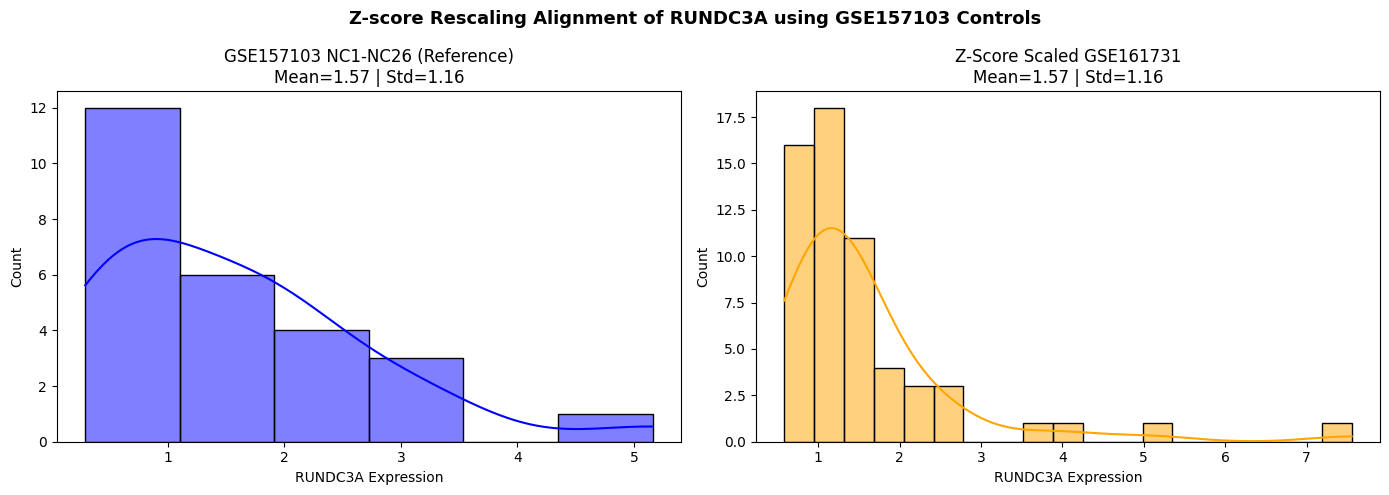

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Isolate strictly NC1 to NC26 from GSE157103 as our reference profile
nc_samples = [f'NC{i}' for i in range(1, 27)]
# Verify all selected samples exist in df_target_precise_aligned
valid_nc_samples = [s for s in nc_samples if s in df_target_precise_aligned.index]
ref_nc_df = df_target_precise_aligned.loc[valid_nc_samples]

# 2. Extract GSE161731 source dataset
src_df = df_gse161731_precise_aligned.copy()

# 3. Perform Z-score mapping based strictly on GSE157103 NC statistics
print(f"Using {len(valid_nc_samples)} control samples (NC1 to NC26) from GSE157103 to calculate reference stats.")

df_zscore_mapped = pd.DataFrame(index=src_df.index, columns=src_df.columns)

for gene in src_df.columns:
    # Reference parameters (NC1 to NC26 only)
    ref_mean = ref_nc_df[gene].mean()
    ref_std = ref_nc_df[gene].std()

    # Source parameters (GSE161731)
    src_mean = src_df[gene].mean()
    src_std = src_df[gene].std()

    if src_std > 0 and ref_std > 0:
        # Convert source to Z-score, then scale to reference parameters
        z_scores = (src_df[gene] - src_mean) / src_std
        df_zscore_mapped[gene] = (z_scores * ref_std) + ref_mean
    else:
        # Fallback to reference mean if no variance is found
        df_zscore_mapped[gene] = ref_mean

# Fill any NaNs that occurred during calculation
df_zscore_mapped = df_zscore_mapped.fillna(0)

# 4. Concatenate the NC reference samples and the newly rescaled GSE161731 samples
df_final_mapped_merged = pd.concat([ref_nc_df, df_zscore_mapped], axis=0)
df_final_mapped_merged.to_csv('merged_non_covid_tpm_zscore_scaled.csv.gz', compression='gzip')

# 5. Display alignment check for 'RUNDC3A'
gene_to_plot = 'RUNDC3A'
print(f"\n=== Statistics for {gene_to_plot} ===")
print(f"Reference NC (GSE157103) - Mean: {ref_nc_df[gene_to_plot].mean():.3f} | Std: {ref_nc_df[gene_to_plot].std():.3f}")
print(f"Rescaled GSE161731       - Mean: {df_zscore_mapped[gene_to_plot].mean():.3f} | Std: {df_zscore_mapped[gene_to_plot].std():.3f} | Min: {df_zscore_mapped[gene_to_plot].min():.3f}")

# Plot the distributions to compare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(ref_nc_df[gene_to_plot], ax=axes[0], kde=True, color='blue')
axes[0].set_title(f"GSE157103 NC1-NC26 (Reference)\nMean={ref_nc_df[gene_to_plot].mean():.2f} | Std={ref_nc_df[gene_to_plot].std():.2f}")
axes[0].set_xlabel(f"{gene_to_plot} Expression")

sns.histplot(df_zscore_mapped[gene_to_plot], ax=axes[1], kde=True, color='orange')
axes[1].set_title(f"Z-Score Scaled GSE161731\nMean={df_zscore_mapped[gene_to_plot].mean():.2f} | Std={df_zscore_mapped[gene_to_plot].std():.2f}")
axes[1].set_xlabel(f"{gene_to_plot} Expression")

plt.suptitle(f"Z-score Rescaling Alignment of {gene_to_plot} using GSE157103 Controls", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# 1. Load the mapped and z-score scaled non-COVID dataset
df_zscore_scaled = pd.read_csv('/content/merged_non_covid_tpm_zscore_scaled.csv.gz', index_col=0)

# 2. Separate GSE157103 NC controls from GSE161731 samples
nc_gse157103 = [s for s in df_zscore_scaled.index if s.startswith('NC')]
gse161731_samples = [s for s in df_zscore_scaled.index if s not in nc_gse157103]

df_nc_gse157103 = df_zscore_scaled.loc[nc_gse157103]
df_gse161731_scaled = df_zscore_scaled.loc[gse161731_samples]

# Rename GSE161731 samples sequentially starting from NC27
num_nc_existing = len(nc_gse157103) # 26
new_names = {old: f'NC{num_nc_existing + i + 1}' for i, old in enumerate(gse161731_samples)}
df_gse161731_scaled_renamed = df_gse161731_scaled.rename(index=new_names)

# Combine back the renamed non-COVID samples
df_non_covid_final = pd.concat([df_nc_gse157103, df_gse161731_scaled_renamed], axis=0)
print(f"Non-COVID final set has shape: {df_non_covid_final.shape} with samples from NC1 to NC{df_non_covid_final.shape[0]}")

# 3. Extract the COVID-19 samples (C1, C2, etc.) from GSE157103
all_target_samples = df_target_transposed.index.tolist()
covid_samples = [s for s in all_target_samples if s.startswith('C') and not s.startswith('NC')]

# Align columns (genes) to the exact same common genes
common_genes = df_non_covid_final.columns
df_covid_gse157103 = df_target_transposed.loc[covid_samples, common_genes]
print(f"Extracted COVID-19 samples shape: {df_covid_gse157103.shape}")

# 4. Concatenate the COVID-19 cases with the complete renamed non-COVID control set
df_final_study = pd.concat([df_covid_gse157103, df_non_covid_final], axis=0)
print(f"Final combined study dataset shape: {df_final_study.shape}")

# Save to a new final combined file
df_final_study.to_csv('/content/merged_study_with_covid_normalized.csv.gz', compression='gzip')
print("Saved final concatenated dataset to '/content/merged_study_with_covid_normalized.csv.gz'")


Non-COVID final set has shape: (85, 18823) with samples from NC1 to NC85
Extracted COVID-19 samples shape: (100, 18823)
Final combined study dataset shape: (185, 18823)
Saved final concatenated dataset to '/content/merged_study_with_covid_normalized.csv.gz'


In [ ]:
df_review = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)
pd.set_option('display.max_rows', None)

# Display the entire merged dataset
print(f"Total rows in merged dataset: {len(df_review)}")
display(df_review)

Total rows in merged dataset: 185


,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,EFNB3,AREL1,DNHD1,CFAP97,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
C1,0.410000,0.290000,3.500000,83.130000,793.950000,0.130000,0.000000,30.100000,1.690000,5.220000,...,464.730000,24.290000,55.980000,1.790000,1.930000,2.260000,10.800000,0.000000,0.890000,0.00
C2,0.380000,0.930000,4.370000,94.440000,990.270000,1.030000,0.000000,28.020000,1.090000,4.580000,...,177.660000,35.440000,99.140000,1.740000,1.690000,2.610000,6.190000,0.000000,1.130000,0.00
C3,0.390000,0.100000,2.240000,41.240000,719.210000,0.000000,0.000000,22.510000,0.660000,1.190000,...,393.770000,6.810000,12.310000,1.860000,0.380000,6.120000,3.590000,0.000000,0.620000,0.00
C4,0.560000,0.190000,7.870000,123.220000,804.480000,0.300000,0.020000,30.870000,1.860000,7.710000,...,256.230000,24.500000,122.510000,3.430000,1.820000,5.010000,9.480000,0.010000,1.590000,0.00
C5,0.450000,0.440000,1.920000,72.720000,505.980000,0.120000,0.020000,28.350000,0.640000,2.590000,...,482.630000,15.100000,44.620000,0.510000,0.210000,3.150000,4.390000,0.000000,0.650000,0.00
C6,1.070000,0.640000,7.630000,92.000000,814.940000,0.300000,0.000000,23.640000,0.790000,5.230000,...,125.340000,42.500000,102.500000,3.000000,1.420000,2.870000,5.060000,0.000000,1.540000,0.00
C7,1.270000,1.170000,9.840000,108.930000,547.310000,0.540000,0.000000,33.450000,2.430000,9.860000,...,129.900000,33.720000,90.030000,2.610000,2.230000,4.520000,12.320000,0.000000,2.190000,0.00
C8,2.920000,1.520000,0.660000,80.360000,601.680000,0.090000,0.000000,33.310000,0.800000,1.530000,...,89.930000,25.350000,34.810000,0.910000,1.480000,1.690000,3.810000,0.030000,0.610000,0.00
C9,0.730000,1.830000,1.570000,82.620000,569.050000,0.220000,0.000000,33.240000,1.590000,4.430000,...,67.800000,21.900000,46.840000,1.250000,4.210000,3.010000,5.020000,0.010000,0.680000,0.00
C10,0.920000,1.210000,1.150000,63.890000,718.240000,0.580000,0.000000,20.360000,0.680000,1.810000,...,85.250000,27.140000,56.680000,1.440000,0.730000,3.250000,3.080000,0.010000,0.540000,0.00


In [ ]:
import pandas as pd
import numpy as np

# 1. Load final study expression dataset
df_final = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)

# Drop old temporary metadata columns if they exist
for col in ['Age', 'Gender', 'ICU']:
    if col in df_final.columns:
        df_final = df_final.drop(columns=[col])

# 2. Parse GSE157103 series matrix metadata
gse157103_meta_file = '/content/GSE157103_series_matrix.txt'
age_dict = {}
gender_dict = {}
icu_dict = {}

with open(gse157103_meta_file, 'r') as f:
    for line in f:
        if line.startswith('!Sample_title'):
            titles = [t.strip('"\n ') for t in line.split('\t')[1:]]
        elif line.startswith('!Sample_characteristics_ch1'):
            characteristics = [c.strip('"\n ') for c in line.split('\t')[1:]]
            for idx, char in enumerate(characteristics):
                if 'age:' in char.lower():
                    val = char.split(':')[-1].strip()
                    age_dict[titles[idx]] = float(val) if val.isdigit() else np.nan
                elif 'gender:' in char.lower() or 'sex:' in char.lower():
                    val = char.split(':')[-1].strip()
                    gender_dict[titles[idx]] = val
                elif 'icu:' in char.lower() or 'icu status:' in char.lower():
                    val = char.split(':')[-1].strip()
                    icu_dict[titles[idx]] = val

# 3. Load GSE161731 key/metadata file
meta_gse161731 = pd.read_csv('/content/GSE161731_key.csv.gz', index_col=0)

# Reconstruct mapping of renamed sample IDs (NC27 - NC85) back to original GSE161731 sample names
# Utilizing the exact order from valid_samples
num_nc_existing = 26
renaming_lookup = {f'NC{num_nc_existing + i + 1}': old for i, old in enumerate(valid_samples)}

# 4. Construct metadata columns
ages_col = []
genders_col = []
icu_col = []

for sample_id in df_final.index:
    if sample_id.startswith('C') and not sample_id.startswith('NC'):
        # COVID sample (GSE157103)
        ages_col.append(age_dict.get(sample_id, np.nan))
        genders_col.append(gender_dict.get(sample_id, np.nan))
        icu_col.append(icu_dict.get(sample_id, np.nan))
    elif sample_id in renaming_lookup:
        # Non-COVID sample from GSE161731 (NC27 to NC85)
        original_id = renaming_lookup[sample_id]
        age_val = meta_gse161731.loc[original_id, 'age']
        gender_val = meta_gse161731.loc[original_id, 'gender']

        # Convert age to float if possible
        try:
            age_val = float(age_val)
        except (ValueError, TypeError):
            age_val = np.nan

        ages_col.append(age_val)
        genders_col.append(gender_val)
        icu_col.append(np.nan) # ICU is NaN for non-COVID samples
    else:
        # Non-COVID reference sample (NC1 to NC26)
        ages_col.append(age_dict.get(sample_id, np.nan))
        genders_col.append(gender_dict.get(sample_id, np.nan))
        icu_col.append(np.nan) # ICU is NaN for non-COVID samples

# 5. Insert variables as the first three columns of the dataframe
df_final.insert(0, 'Age', ages_col)
df_final.insert(1, 'Gender', genders_col)

# Convert ICU data values to standardized representation (e.g., 'yes', 'no')
standardized_icu = [str(x).lower() if pd.notna(x) else np.nan for x in icu_col]
df_final.insert(2, 'ICU', standardized_icu)

# Save the final dataset
df_final.to_csv('/content/merged_study_with_covid_normalized.csv.gz', compression='gzip')
print("Metadata columns successfully aligned and saved!")

# Preview a portion of COVID-19 samples and NC samples to verify
print("\n--- Preview of COVID-19 samples: ---")
display(df_final.loc[[s for s in df_final.index if s.startswith('C')][:5], ['Age', 'Gender', 'ICU']])
print("\n--- Preview of GSE157103 NC samples: ---")
display(df_final.loc[[f'NC{i}' for i in range(1, 6)], ['Age', 'Gender', 'ICU']])
print("\n--- Preview of GSE161731 NC samples: ---")
display(df_final.loc[[f'NC{i}' for i in range(27, 32)], ['Age', 'Gender', 'ICU']])

/tmp/ipykernel_4595/1034781166.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_final = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)


Metadata columns successfully aligned and saved!

--- Preview of COVID-19 samples: ---


,Age,Gender,ICU
C1,NaN,NaN,NaN
C2,NaN,NaN,NaN
C3,NaN,NaN,NaN
C4,NaN,NaN,NaN
C5,NaN,NaN,NaN



--- Preview of GSE157103 NC samples: ---


,Age,Gender,ICU
NC1,NaN,NaN,NaN
NC2,NaN,NaN,NaN
NC3,NaN,NaN,NaN
NC4,NaN,NaN,NaN
NC5,NaN,NaN,NaN



--- Preview of GSE161731 NC samples: ---


,Age,Gender,ICU
NC27,57.0,Female,NaN
NC28,19.0,Male,NaN
NC29,14.0,Male,NaN
NC30,21.0,Female,NaN
NC31,50.0,Female,NaN


In [ ]:
import pandas as pd
import numpy as np
import re

# 1. Load final study expression dataset
df_final = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)

# Drop the old metadata columns to do a clean insert
for col in ['Age', 'Gender', 'ICU']:
    if col in df_final.columns:
        df_final = df_final.drop(columns=[col])

# 2. Parse GSE157103 series matrix file
gse157103_meta_file = '/content/GSE157103_series_matrix.txt'

sample_geo_accessions = []
sample_titles = []
age_list = []
gender_list = []
icu_list = []

with open(gse157103_meta_file, 'r') as f:
    for line in f:
        if line.startswith('!Sample_title'):
            sample_titles = [t.strip('"\n ') for t in line.split('\t')[1:]]
        elif line.startswith('!Sample_geo_accession'):
            sample_geo_accessions = [g.strip('"\n ') for g in line.split('\t')[1:]]
        elif line.startswith('!Sample_characteristics_ch1'):
            characteristics = [c.strip('"\n ') for c in line.split('\t')[1:]]
            for idx, char in enumerate(characteristics):
                if 'age:' in char.lower():
                    val = char.split(':')[-1].strip()
                    age_list.append(float(val) if (val.isdigit() or val.replace('.', '', 1).isdigit()) else np.nan)
                elif 'gender:' in char.lower() or 'sex:' in char.lower():
                    val = char.split(':')[-1].strip().lower()
                    gender_list.append(val)
                elif 'icu:' in char.lower() or 'icu status:' in char.lower():
                    val = char.split(':')[-1].strip().lower()
                    icu_list.append(val)

# Match lists to build structured mapping
gse157103_meta = {}
for idx, title in enumerate(sample_titles):
    geo = sample_geo_accessions[idx]
    # Standardize Gender (female/male)
    gender = gender_list[idx] if idx < len(gender_list) else np.nan
    # Standardize ICU (yes/no)
    icu = icu_list[idx] if idx < len(icu_list) else np.nan
    age = age_list[idx] if idx < len(age_list) else np.nan

    gse157103_meta[title] = {'Age': age, 'Gender': gender, 'ICU': icu}
    gse157103_meta[geo] = {'Age': age, 'Gender': gender, 'ICU': icu}

# Create mappings specifically for C1-C102 and NC1-NC26 based on title structures
# Sample Titles pattern in matrix file:
# 'COVID_01_39y_male_NonICU' corresponds to COVID ID 1 -> 'C1'
# 'NonCOVID_01_74y_female' corresponds to Non-COVID ID 1 -> 'NC1'
resolved_meta = {}
for title, data in gse157103_meta.items():
    if 'COVID' in title and 'NonCOVID' not in title:
        match = re.search(r'COVID_(\d+)_', title)
        if match:
            clean_id = f'C{int(match.group(1))}'
            resolved_meta[clean_id] = data
    elif 'NonCOVID' in title:
        match = re.search(r'NonCOVID_(\d+)_', title)
        if match:
            clean_id = f'NC{int(match.group(1))}'
            resolved_meta[clean_id] = data

# 3. Load GSE161731 key/metadata file for (NC27 to NC85)
meta_gse161731 = pd.read_csv('/content/GSE161731_key.csv.gz', index_col=0)
num_nc_existing = 26
renaming_lookup = {f'NC{num_nc_existing + i + 1}': old for i, old in enumerate(valid_samples)}

# 4. Construct final metadata columns
ages_col = []
genders_col = []
icu_col = []

for sample_id in df_final.index:
    if sample_id in resolved_meta:
        # GSE157103 Samples (C1-C102, NC1-NC26)
        ages_col.append(resolved_meta[sample_id]['Age'])
        genders_col.append(resolved_meta[sample_id]['Gender'])
        # Ensure non-COVID control samples have ICU forced to NaN
        if sample_id.startswith('NC'):
            icu_col.append(np.nan)
        else:
            icu_col.append(resolved_meta[sample_id]['ICU'])
    elif sample_id in renaming_lookup:
        # GSE161731 Samples (NC27-NC85)
        original_id = renaming_lookup[sample_id]
        age_val = meta_gse161731.loc[original_id, 'age']
        gender_val = meta_gse161731.loc[original_id, 'gender']

        try:
            age_val = float(age_val)
        except (ValueError, TypeError):
            age_val = np.nan

        ages_col.append(age_val)
        genders_col.append(str(gender_val).lower() if pd.notna(gender_val) else np.nan)
        icu_col.append(np.nan) # Controls forced to NaN
    else:
        ages_col.append(np.nan)
        genders_col.append(np.nan)
        icu_col.append(np.nan)

# 5. Insert variables as leading columns
df_final.insert(0, 'Age', ages_col)
df_final.insert(1, 'Gender', genders_col)
df_final.insert(2, 'ICU', icu_col)

# Save the final dataset
df_final.to_csv('/content/merged_study_with_covid_normalized.csv.gz', compression='gzip')
print("Metadata columns successfully mapped, aligned, and saved!")

# Preview to verify the mappings are populated correctly
print("\n--- Preview of COVID-19 samples (C1-C5): ---")
display(df_final.loc[['C1', 'C2', 'C3', 'C4', 'C5'], ['Age', 'Gender', 'ICU']])
print("\n--- Preview of GSE157103 NC samples (NC1-NC5): ---")
display(df_final.loc[['NC1', 'NC2', 'NC3', 'NC4', 'NC5'], ['Age', 'Gender', 'ICU']])
print("\n--- Preview of GSE161731 NC samples (NC27-NC31): ---")
display(df_final.loc[['NC27', 'NC28', 'NC29', 'NC30', 'NC31'], ['Age', 'Gender', 'ICU']])

/tmp/ipykernel_4595/61207103.py:6: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_final = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)


Metadata columns successfully mapped, aligned, and saved!

--- Preview of COVID-19 samples (C1-C5): ---


,Age,Gender,ICU
C1,NaN,female,no
C2,NaN,male,yes
C3,NaN,male,yes
C4,NaN,male,no
C5,NaN,female,no



--- Preview of GSE157103 NC samples (NC1-NC5): ---


,Age,Gender,ICU
NC1,NaN,NaN,NaN
NC2,NaN,NaN,NaN
NC3,NaN,NaN,NaN
NC4,NaN,NaN,NaN
NC5,NaN,NaN,NaN



--- Preview of GSE161731 NC samples (NC27-NC31): ---


,Age,Gender,ICU
NC27,57.0,female,NaN
NC28,19.0,male,NaN
NC29,14.0,male,NaN
NC30,21.0,female,NaN
NC31,50.0,female,NaN


In [ ]:
df_reveiw = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)
pd.set_option(
    'display.max_rows', None)

# Display the entire merged dataset
print(f"Total rows in merged dataset: {len(df_reveiw)}")
display(df_reveiw)

/tmp/ipykernel_4595/2818668519.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_reveiw = pd.read_csv('/content/merged_study_with_covid_normalized.csv.gz', index_col=0)


Total rows in merged dataset: 185


,Age,Gender,ICU,class,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
C1,NaN,female,no,Covid,0.410000,0.290000,3.500000,83.130000,793.950000,0.130000,...,464.730000,24.290000,55.980000,1.790000,1.930000,2.260000,10.800000,0.000000,0.890000,0.00
C2,NaN,male,yes,Covid,0.380000,0.930000,4.370000,94.440000,990.270000,1.030000,...,177.660000,35.440000,99.140000,1.740000,1.690000,2.610000,6.190000,0.000000,1.130000,0.00
C3,NaN,male,yes,Covid,0.390000,0.100000,2.240000,41.240000,719.210000,0.000000,...,393.770000,6.810000,12.310000,1.860000,0.380000,6.120000,3.590000,0.000000,0.620000,0.00
C4,NaN,male,no,Covid,0.560000,0.190000,7.870000,123.220000,804.480000,0.300000,...,256.230000,24.500000,122.510000,3.430000,1.820000,5.010000,9.480000,0.010000,1.590000,0.00
C5,NaN,female,no,Covid,0.450000,0.440000,1.920000,72.720000,505.980000,0.120000,...,482.630000,15.100000,44.620000,0.510000,0.210000,3.150000,4.390000,0.000000,0.650000,0.00
C6,NaN,female,yes,Covid,1.070000,0.640000,7.630000,92.000000,814.940000,0.300000,...,125.340000,42.500000,102.500000,3.000000,1.420000,2.870000,5.060000,0.000000,1.540000,0.00
C7,NaN,male,yes,Covid,1.270000,1.170000,9.840000,108.930000,547.310000,0.540000,...,129.900000,33.720000,90.030000,2.610000,2.230000,4.520000,12.320000,0.000000,2.190000,0.00
C8,NaN,female,yes,Covid,2.920000,1.520000,0.660000,80.360000,601.680000,0.090000,...,89.930000,25.350000,34.810000,0.910000,1.480000,1.690000,3.810000,0.030000,0.610000,0.00
C9,NaN,female,no,Covid,0.730000,1.830000,1.570000,82.620000,569.050000,0.220000,...,67.800000,21.900000,46.840000,1.250000,4.210000,3.010000,5.020000,0.010000,0.680000,0.00
C10,NaN,male,yes,Covid,0.920000,1.210000,1.150000,63.890000,718.240000,0.580000,...,85.250000,27.140000,56.680000,1.440000,0.730000,3.250000,3.080000,0.010000,0.540000,0.00
